# QPE 小时累计与 RMSE

对 `resource/data` 下一小时内多时次 Z9010 基数据批量做质控与 QPE，将瞬时降水率（mm/h）梯形积分成近一小时累计（mm），再与 `resource/CMPAS_APCP` 实况对比、算 RMSE 并画图。

流程概要：

1. 按文件名时间排序体扫；每个时次：`radar_qc_cli.process`（极坐标质控 CLI）→ 指定仰角 REF/KDP → 算降水率
2. 对相邻时次降水率做梯形积分，得到方法各自的 1h 累计场
3. 读取 CMPAS 近一小时累计，裁剪到雷达范围后插值到雷达网格，计算 RMSE 并对比出图

说明：本样例雷达文件名时次为 19:00–20:00，实况为 `BJT_25072420.000.nc`（`time=2025-07-24 20:00`）。本 notebook 按同一套时钟对齐该小时窗，不做时区换算。


## 环境与路径

In [1]:
%matplotlib inline

import re
import sys
import warnings
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import meteva_base as meb
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap
from meteva_base.tool.color_tools import get_cmap_and_clevs_by_element_name
from meteva_base.tool.plot_tools import pcolormesh_2d_grid

NOTEBOOK_DIR = Path.cwd().resolve()
PKG_DIR = NOTEBOOK_DIR.parent
REPO_ROOT = PKG_DIR.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from radar_qpe_retrieval.cli.radar_qc_cli import process as radar_qc_process
from radar_qpe_retrieval.src.qpe import QPEPlugin

RESOURCE_DIR = PKG_DIR / "resource"
RADAR_DIR = RESOURCE_DIR / "data"
OBS_DIR = RESOURCE_DIR / "CMPAS_APCP"
DEM_PATH = (
    REPO_ROOT
    / "orographic_wind_downscaling"
    / "resource"
    / "data"
    / "HGT_M_1KM_CHINA.nc"
)
OUT_DIR = NOTEBOOK_DIR / "_qpe_hourly_rmse_out"
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.family"] = "SimHei"
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("PKG_DIR =", PKG_DIR)
print("RADAR_DIR =", RADAR_DIR)
print("OBS_DIR =", OBS_DIR)
print("DEM_PATH =", DEM_PATH, "exists=", DEM_PATH.is_file())


d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


PKG_DIR = D:\workspace\test\00temp\radar_qpe_retrieval
RADAR_DIR = D:\workspace\test\00temp\radar_qpe_retrieval\resource\data
OBS_DIR = D:\workspace\test\00temp\radar_qpe_retrieval\resource\CMPAS_APCP


## 参数与工具函数

In [2]:
# ---- 运行参数 ----
RANGE_KM = 300
RESOLUTION = (1000, 1000)
SWEEP_INDEX = 0  # 统一用最低仰角层（本数据约 0.48°）

# 质控阈值（PolarRadarQCPlugin）
QC_MIN_REFL_DBZ = 15.0
QC_MIN_RHO = 0.85
QC_MAX_DBZ = 80.0

# 小时窗：默认对齐 CMPAS 文件时间；也可手动指定
OBS_FILE = OBS_DIR / "BJT_25072420.000.nc"
HOUR_END = None  # None 时用实况 time；也可写 datetime(2025, 7, 24, 20, 0, 0)

# 对比方法及构造参数（瞬时率 → 再积分）
# 业务常用：S 波段默认系数；zkdp 以 R(Z) 为主，R(Z)>thresh 切到 R(KDP)
METHOD_SPECS = {
    "z": dict(method="z", z_alpha=0.0376, z_beta=0.6112),
    "zpoly": dict(method="zpoly"),
    "ztor": dict(method="ztor", ztor_a=300.0, ztor_b=1.4),
    "kdp": dict(method="kdp", kdp_alpha=50.70, kdp_beta=0.85),
    "zkdp": dict(
        method="zkdp",
        z_alpha=0.0376,
        z_beta=0.6112,
        kdp_alpha=50.70,
        kdp_beta=0.85,
        main_field="refl",
        thresh=40.0,
        thresh_max=True,
    ),
}

RADAR_NAME_RE = re.compile(r"_(\d{14})_")


def create_qpe_discrete_cmap():
    """QPE / 小时累计离散色标（与 qpe.ipynb 一致）。"""
    bounds = [0.0, 0.1, 10.0, 25.0, 50.0, 100.0, 250.0]
    colors = [
        (1.0, 1.0, 1.0),
        (0.631, 0.945, 0.553),
        (0.239, 0.729, 0.239),
        (0.376, 0.722, 1.0),
        (0.0, 0.0, 1.0),
        (0.980, 0.0, 0.980),
    ]
    labels = ["0~<0.1", "0.1~<10", "10~<25", "25~<50", "50~<100", "100~<250"]
    cmap = ListedColormap(colors, name="qpe_precip_class")
    cmap.set_bad((1.0, 1.0, 1.0, 1.0))
    cmap.set_under((1.0, 1.0, 1.0, 1.0))
    ticks = [(bounds[i] + bounds[i + 1]) / 2.0 for i in range(len(labels))]
    return cmap, BoundaryNorm(bounds, cmap.N, clip=True), ticks, labels


def parse_radar_time(path: Path) -> datetime:
    m = RADAR_NAME_RE.search(path.name)
    if m is None:
        raise ValueError(f"无法从文件名解析时间: {path.name}")
    return datetime.strptime(m.group(1), "%Y%m%d%H%M%S")


def list_radar_files(radar_dir: Path) -> list[tuple[datetime, Path]]:
    files = sorted(radar_dir.glob("Z_RADR_I_*.bin.bz2"))
    items = [(parse_radar_time(p), p) for p in files]
    items.sort(key=lambda x: x[0])
    return items


def filter_hour_window(
    items: list[tuple[datetime, Path]],
    hour_end: datetime,
) -> list[tuple[datetime, Path]]:
    """选取 [hour_end-1h, hour_end] 闭区间内的体扫。"""
    hour_start = hour_end - timedelta(hours=1)
    return [(t, p) for t, p in items if hour_start <= t <= hour_end]


def squeeze2d(da: xr.DataArray) -> np.ndarray:
    return np.asarray(np.squeeze(da.values), dtype=np.float32)


def as_meb_2d(da: xr.DataArray, name: str, units: str) -> xr.DataArray:
    """保留 meb 六维坐标，仅改 name/units，便于 pcolormesh_2d_grid。"""
    out = da.copy(deep=True)
    out.name = name
    out.attrs = dict(da.attrs)
    out.attrs["units"] = units
    return out

In [3]:
def process_one_volume(
    path: Path,
    *,
    method_specs: dict,
    range_km: int = RANGE_KM,
    resolution=RESOLUTION,
    sweep_index: int = SWEEP_INDEX,
) -> dict:
    """单时次：极坐标质控 + 多方法瞬时降水率（mm/h）。"""
    qc_out = radar_qc_process(
        input_path=str(path),
        radius=range_km,
        resolution=resolution,
        sweep=sweep_index,
        dem_path=str(DEM_PATH) if DEM_PATH.is_file() else None,
        min_refl_dbz=QC_MIN_REFL_DBZ,
        max_refl_dbz=QC_MAX_DBZ,
        min_rho=QC_MIN_RHO,
        use_zdr=True,
        use_phidp_texture=True,
        use_kdp_texture=True,
        despeckle=True,
        despeckle_size=10,
    )
    refl0, kdp0, att0 = qc_out["refl"], qc_out["kdp"], qc_out["att"]
    gatefilter = qc_out["gatefilter"]

    rates = {}
    for name, kwargs in method_specs.items():
        plugin = QPEPlugin(**kwargs)
        method = kwargs["method"]
        if method in ("z", "zpoly", "ztor"):
            rates[name] = plugin.process(refl=refl0)
        elif method == "kdp":
            rates[name] = plugin.process(kdp=kdp0)
        elif method == "zkdp":
            rates[name] = plugin.process(refl=refl0, kdp=kdp0)
        else:
            raise ValueError(f"本 notebook 未配置 method={method}")

    valid_frac = float(np.isfinite(squeeze2d(refl0)).mean())
    elev = float(np.asarray(refl0.level.values).reshape(-1)[0])
    return {
        "path": path,
        "elev_deg": elev,
        "valid_frac": valid_frac,
        "excluded_frac": float(np.asarray(gatefilter.gate_excluded).mean()),
        "refl0": refl0,
        "kdp0": kdp0,
        "rates": rates,
    }


def accumulate_hourly_rates(
    times: list[datetime],
    rate_arrays: list[np.ndarray],
) -> np.ndarray:
    """瞬时率 mm/h → 小时累计 mm（相邻时次梯形积分）。"""
    if len(times) < 2:
        raise ValueError("至少需要 2 个时次才能积分小时累计")
    acc = np.zeros_like(rate_arrays[0], dtype=np.float64)
    weight = np.zeros_like(rate_arrays[0], dtype=np.float64)
    for i in range(len(times) - 1):
        dt_h = (times[i + 1] - times[i]).total_seconds() / 3600.0
        if dt_h <= 0:
            raise ValueError(f"时次未递增: {times[i]} -> {times[i + 1]}")
        a = rate_arrays[i].astype(np.float64, copy=False)
        b = rate_arrays[i + 1].astype(np.float64, copy=False)
        both = np.isfinite(a) & np.isfinite(b)
        only_a = np.isfinite(a) & ~np.isfinite(b)
        only_b = np.isfinite(b) & ~np.isfinite(a)
        seg = np.full_like(a, np.nan, dtype=np.float64)
        seg[both] = 0.5 * (a[both] + b[both]) * dt_h
        seg[only_a] = a[only_a] * dt_h
        seg[only_b] = b[only_b] * dt_h
        ok = np.isfinite(seg)
        acc[ok] += seg[ok]
        weight[ok] += 1.0
    out = np.full_like(acc, np.nan, dtype=np.float32)
    ok = weight > 0
    out[ok] = acc[ok].astype(np.float32)
    return out


def load_cmpas_obs(path: Path) -> xr.DataArray:
    with xr.open_dataset(path) as ds:
        da = ds["data0"].astype(np.float32).load()
    da = da.where(da >= 0)  # 负值作缺测
    da.name = "obs_rain_1h"
    da.attrs["units"] = "mm"
    return da


def crop_obs_to_radar(obs: xr.DataArray, radar_da: xr.DataArray, pad_deg: float = 0.2) -> xr.DataArray:
    lat = np.asarray(radar_da.lat.values)
    lon = np.asarray(radar_da.lon.values)
    return obs.sel(
        lat=slice(float(lat.min()) - pad_deg, float(lat.max()) + pad_deg),
        lon=slice(float(lon.min()) - pad_deg, float(lon.max()) + pad_deg),
    )


def interp_obs_to_radar(obs_crop: xr.DataArray, radar_da: xr.DataArray) -> xr.DataArray:
    """将实况插值到雷达 meb 网格（保留六维结构）。"""
    obs2 = obs_crop
    while obs2.ndim > 2:
        # 去掉 member/level/time/dtime 等长度为 1 的维
        for dim in list(obs2.dims):
            if dim not in ("lat", "lon") and obs2.sizes.get(dim, 0) == 1:
                obs2 = obs2.isel({dim: 0})
                break
        else:
            break
    interp = obs2.interp(
        lat=radar_da.lat,
        lon=radar_da.lon,
        method="linear",
    )
    # 对齐到 radar 六维壳
    vals = np.asarray(interp.values, dtype=np.float32)
    shell = np.full(radar_da.shape, np.nan, dtype=np.float32)
    shell[...] = vals.reshape(shell.shape)
    out = radar_da.copy(deep=True)
    out.values = shell
    out.name = "obs_rain_1h"
    out.attrs = {"units": "mm", "long_name": "CMPAS 1h precipitation on radar grid"}
    return out


def calc_rmse(pred: np.ndarray, obs: np.ndarray) -> dict:
    mask = np.isfinite(pred) & np.isfinite(obs)
    n = int(mask.sum())
    if n == 0:
        return {"n": 0, "rmse": np.nan, "bias": np.nan, "mae": np.nan, "corr": np.nan}
    d = pred[mask] - obs[mask]
    rmse = float(np.sqrt(np.mean(d ** 2)))
    bias = float(np.mean(d))
    mae = float(np.mean(np.abs(d)))
    if n > 1 and np.std(pred[mask]) > 0 and np.std(obs[mask]) > 0:
        corr = float(np.corrcoef(pred[mask], obs[mask])[0, 1])
    else:
        corr = np.nan
    return {"n": n, "rmse": rmse, "bias": bias, "mae": mae, "corr": corr}


def valid_data_box(arrays: list[np.ndarray], lat: np.ndarray, lon: np.ndarray, pad: float = 0.05):
    mask = np.zeros_like(arrays[0], dtype=bool)
    for a in arrays:
        mask |= np.isfinite(a)
    if not mask.any():
        return dict(lon=slice(float(lon.min()), float(lon.max())), lat=slice(float(lat.min()), float(lat.max())))
    yy, xx = np.where(mask)
    return dict(
        lon=slice(float(lon[xx.min()]) - pad, float(lon[xx.max()]) + pad),
        lat=slice(float(lat[yy.min()]) - pad, float(lat[yy.max()]) + pad),
    )


## 批量调度：质控 + 瞬时降水率

In [4]:
obs_raw = load_cmpas_obs(OBS_FILE)
hour_end = HOUR_END or pd.to_datetime(obs_raw.time.values[0]).to_pydatetime()
all_items = list_radar_files(RADAR_DIR)
hour_items = filter_hour_window(all_items, hour_end)

print(f"实况: {OBS_FILE.name}, time={hour_end}")
print(f"小时窗内体扫数: {len(hour_items)}")
for t, p in hour_items:
    print(" ", t.strftime("%Y-%m-%d %H:%M:%S"), p.name)

if len(hour_items) < 2:
    raise RuntimeError("小时窗内体扫不足 2 个，无法积分")

实况: BJT_25072420.000.nc, time=2025-07-24 20:00:00
小时窗内体扫数: 11
  2025-07-24 19:00:01 Z_RADR_I_Z9010_20250724190001_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 19:06:01 Z_RADR_I_Z9010_20250724190601_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 19:12:01 Z_RADR_I_Z9010_20250724191201_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 19:18:00 Z_RADR_I_Z9010_20250724191800_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 19:24:00 Z_RADR_I_Z9010_20250724192400_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 19:30:01 Z_RADR_I_Z9010_20250724193001_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 19:36:00 Z_RADR_I_Z9010_20250724193600_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 19:42:01 Z_RADR_I_Z9010_20250724194201_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 19:48:01 Z_RADR_I_Z9010_20250724194801_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 19:54:00 Z_RADR_I_Z9010_20250724195400_O_DOR_SAD_CAP_FMT.bin.bz2
  2025-07-24 20:00:00 Z_RADR_I_Z9010_20250724200000_O_DOR_SAD_CAP_FMT.bin.bz2


In [5]:
volume_results = []
for i, (t, path) in enumerate(hour_items, start=1):
    print(f"[{i}/{len(hour_items)}] {t}  {path.name}")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        result = process_one_volume(path, method_specs=METHOD_SPECS)
    result["time"] = t
    volume_results.append(result)
    print(
        f"  elev={result['elev_deg']:.2f}°, excluded_frac={result['excluded_frac']}, "
        f"valid_frac={result['valid_frac']:.3%}"
    )

template_da = volume_results[0]["rates"][next(iter(METHOD_SPECS))]
print("网格 shape:", template_da.shape, "level=", float(template_da.level.values[0]))


[1/11] 2025-07-24 19:00:01  Z_RADR_I_Z9010_20250724190001_O_DOR_SAD_CAP_FMT.bin.bz2
  elev=0.48°, low_tilt_idx=0, valid_frac=10.671%
[2/11] 2025-07-24 19:06:01  Z_RADR_I_Z9010_20250724190601_O_DOR_SAD_CAP_FMT.bin.bz2
  elev=0.48°, low_tilt_idx=0, valid_frac=10.860%
[3/11] 2025-07-24 19:12:01  Z_RADR_I_Z9010_20250724191201_O_DOR_SAD_CAP_FMT.bin.bz2
  elev=0.48°, low_tilt_idx=0, valid_frac=11.001%
[4/11] 2025-07-24 19:18:00  Z_RADR_I_Z9010_20250724191800_O_DOR_SAD_CAP_FMT.bin.bz2
  elev=0.48°, low_tilt_idx=0, valid_frac=11.158%
[5/11] 2025-07-24 19:24:00  Z_RADR_I_Z9010_20250724192400_O_DOR_SAD_CAP_FMT.bin.bz2
  elev=0.48°, low_tilt_idx=0, valid_frac=11.258%
[6/11] 2025-07-24 19:30:01  Z_RADR_I_Z9010_20250724193001_O_DOR_SAD_CAP_FMT.bin.bz2
  elev=0.48°, low_tilt_idx=0, valid_frac=11.420%
[7/11] 2025-07-24 19:36:00  Z_RADR_I_Z9010_20250724193600_O_DOR_SAD_CAP_FMT.bin.bz2
  elev=0.48°, low_tilt_idx=0, valid_frac=11.455%
[8/11] 2025-07-24 19:42:01  Z_RADR_I_Z9010_20250724194201_O_DOR_SAD_C

## 瞬时率 → 近一小时累计，并与实况对齐

In [6]:
times = [r["time"] for r in volume_results]
hourly = {}
for method_name in METHOD_SPECS:
    rate_list = [squeeze2d(r["rates"][method_name]) for r in volume_results]
    hourly[method_name] = accumulate_hourly_rates(times, rate_list)
    print(
        method_name,
        "finite=",
        int(np.isfinite(hourly[method_name]).sum()),
        "max=",
        float(np.nanmax(hourly[method_name])),
    )

obs_crop = crop_obs_to_radar(obs_raw, template_da)
obs_on_radar = interp_obs_to_radar(obs_crop, template_da)
obs2d = squeeze2d(obs_on_radar)

# 组装 meb 场便于绑图
hourly_da = {
    name: as_meb_2d(
        template_da.copy(deep=True),
        name=f"qpe_1h_{name}",
        units="mm",
    )
    for name in METHOD_SPECS
}
for name, arr in hourly.items():
    hourly_da[name].values = arr.reshape(hourly_da[name].shape)

stats_rows = []
for name, arr in hourly.items():
    s = calc_rmse(arr, obs2d)
    s["method"] = name
    stats_rows.append(s)
stats_df = pd.DataFrame(stats_rows)[["method", "n", "rmse", "mae", "bias", "corr"]]
stats_df = stats_df.sort_values("rmse").reset_index(drop=True)
print(stats_df.to_string(index=False))
stats_df.to_csv(OUT_DIR / "rmse_summary.csv", index=False, float_format="%.4f")
print("已写出", OUT_DIR / "rmse_summary.csv")

z finite= 224790 max= 38.236812591552734
zpoly finite= 224790 max= 87.49858093261719
ztor finite= 224790 max= 56.41720962524414
kdp finite= 212993 max= 85.41438293457031
zkdp finite= 224789 max= 50.75009536743164
method      n     rmse      mae      bias     corr
     z 224790 5.701035 2.744084 -0.027805 0.197142
  zkdp 224789 5.806365 2.773993  0.007579 0.193141
  ztor 224790 6.236534 2.930944  0.217502 0.199719
 zpoly 224790 6.848324 3.107702  0.436853 0.191226
   kdp 212993 9.236121 4.878387  2.916246 0.248099
已写出 D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\rmse_summary.csv


## 画图对比

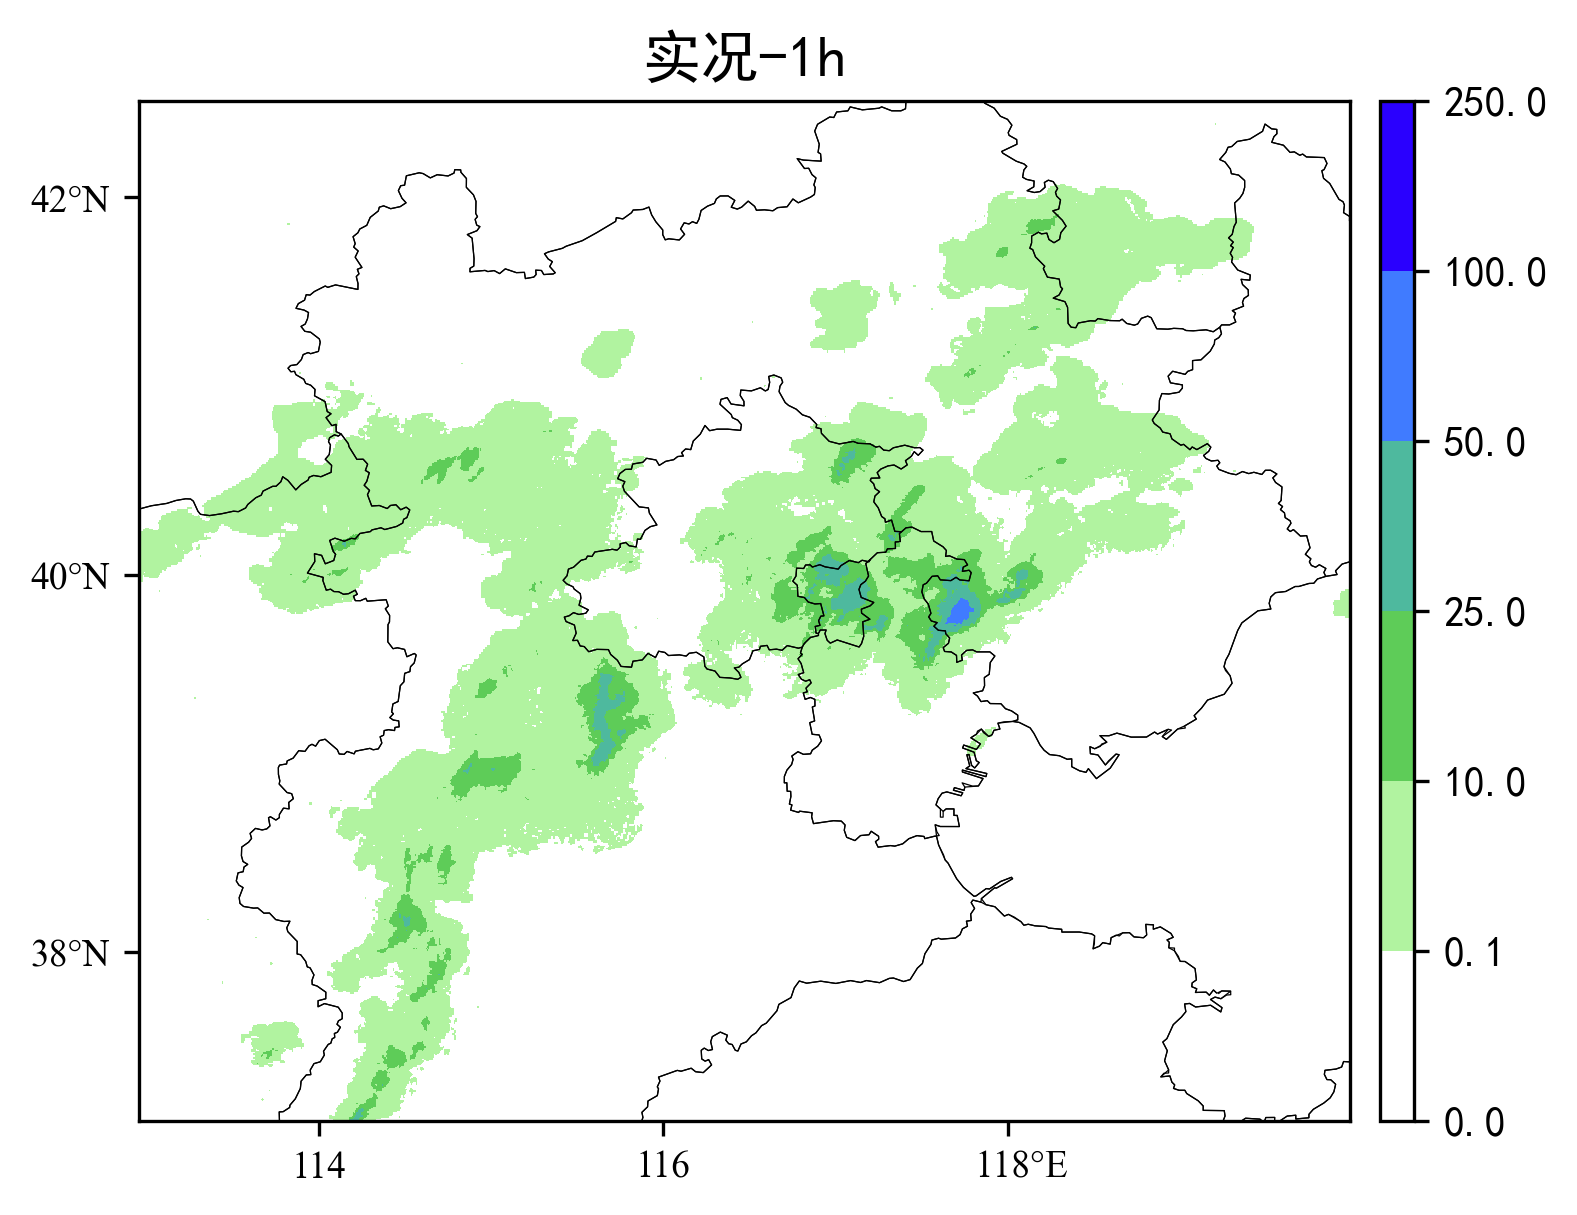

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\obs_1h.png


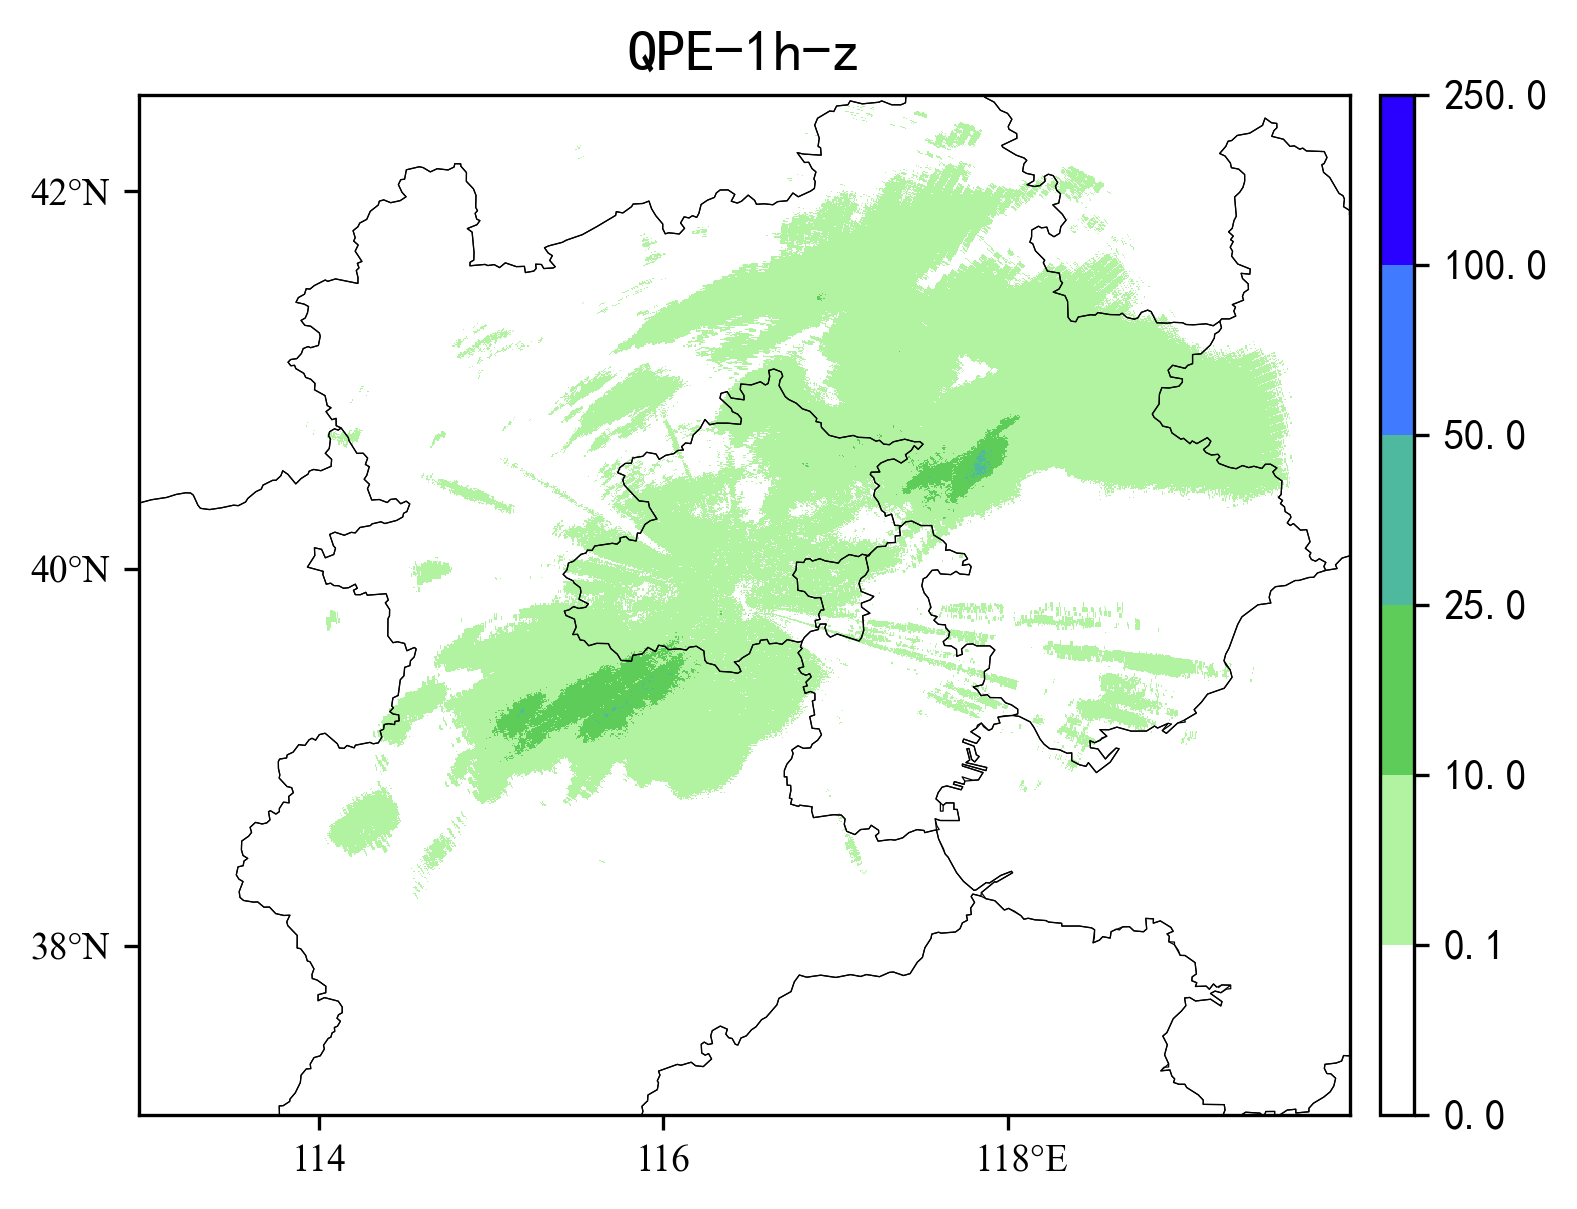

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\z_1h.png


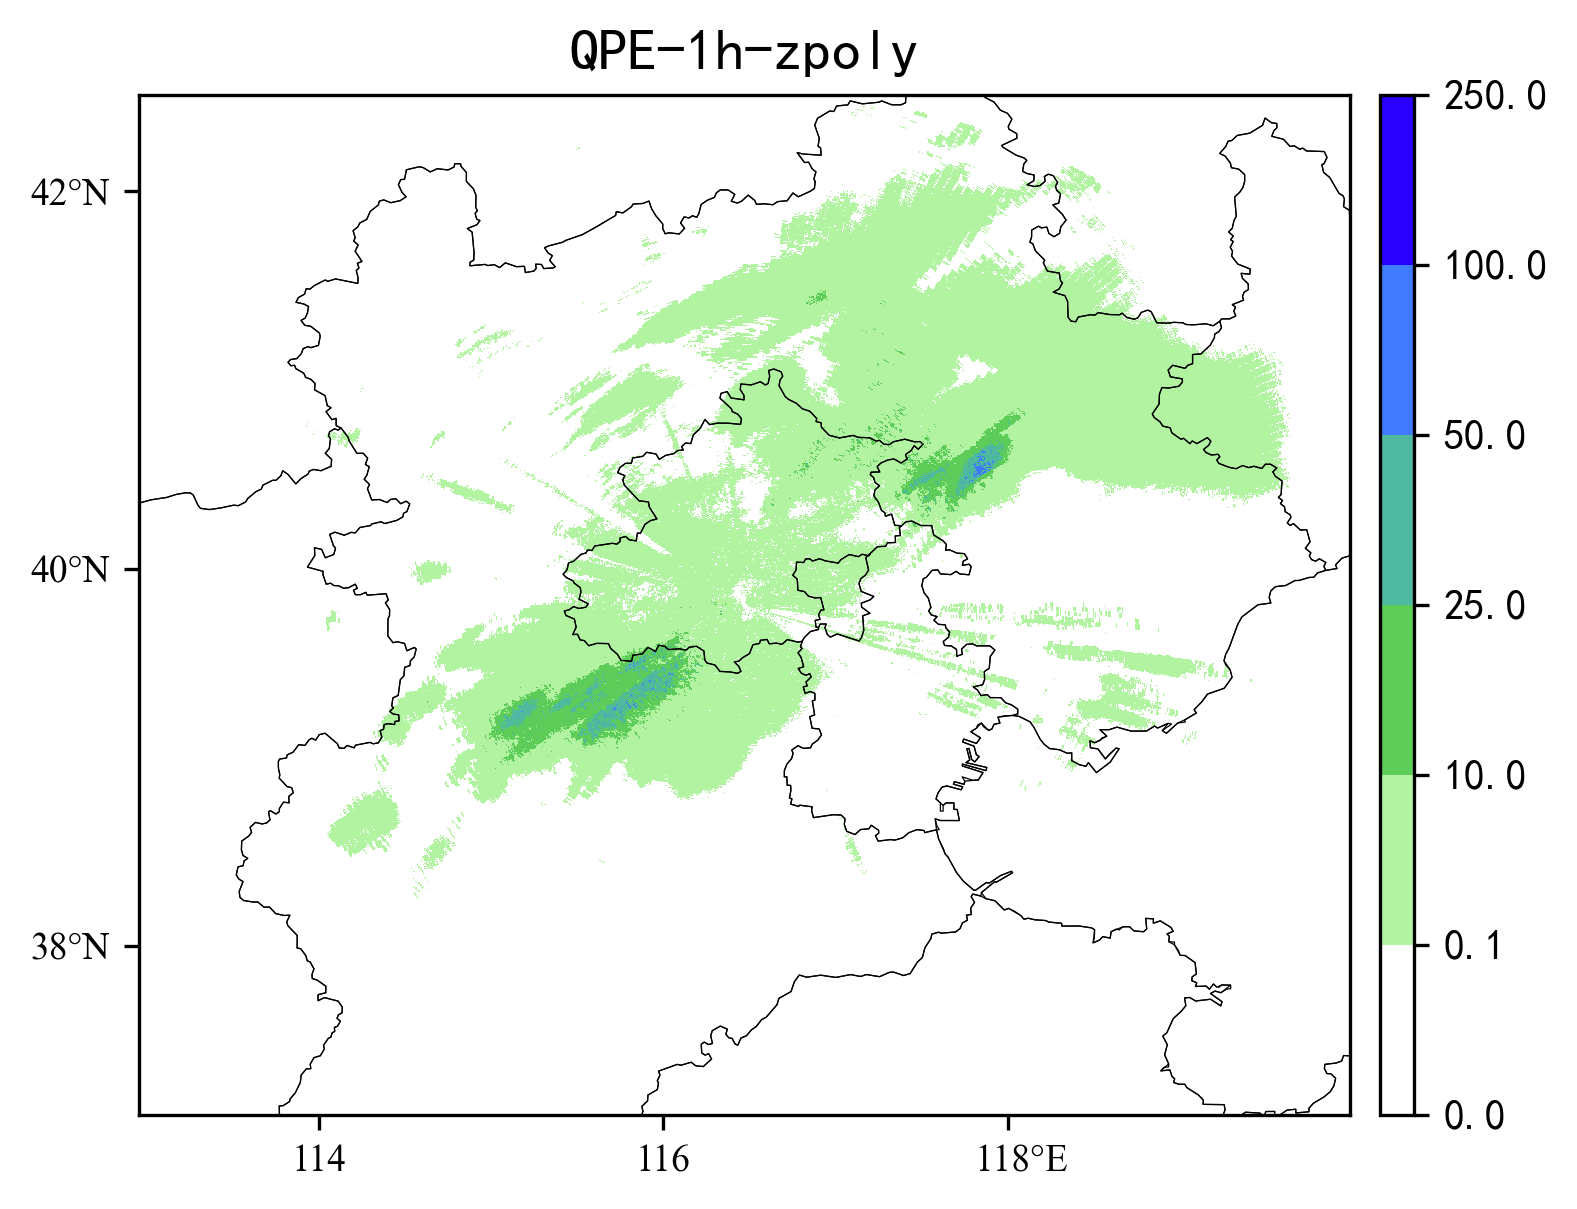

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\zpoly_1h.png


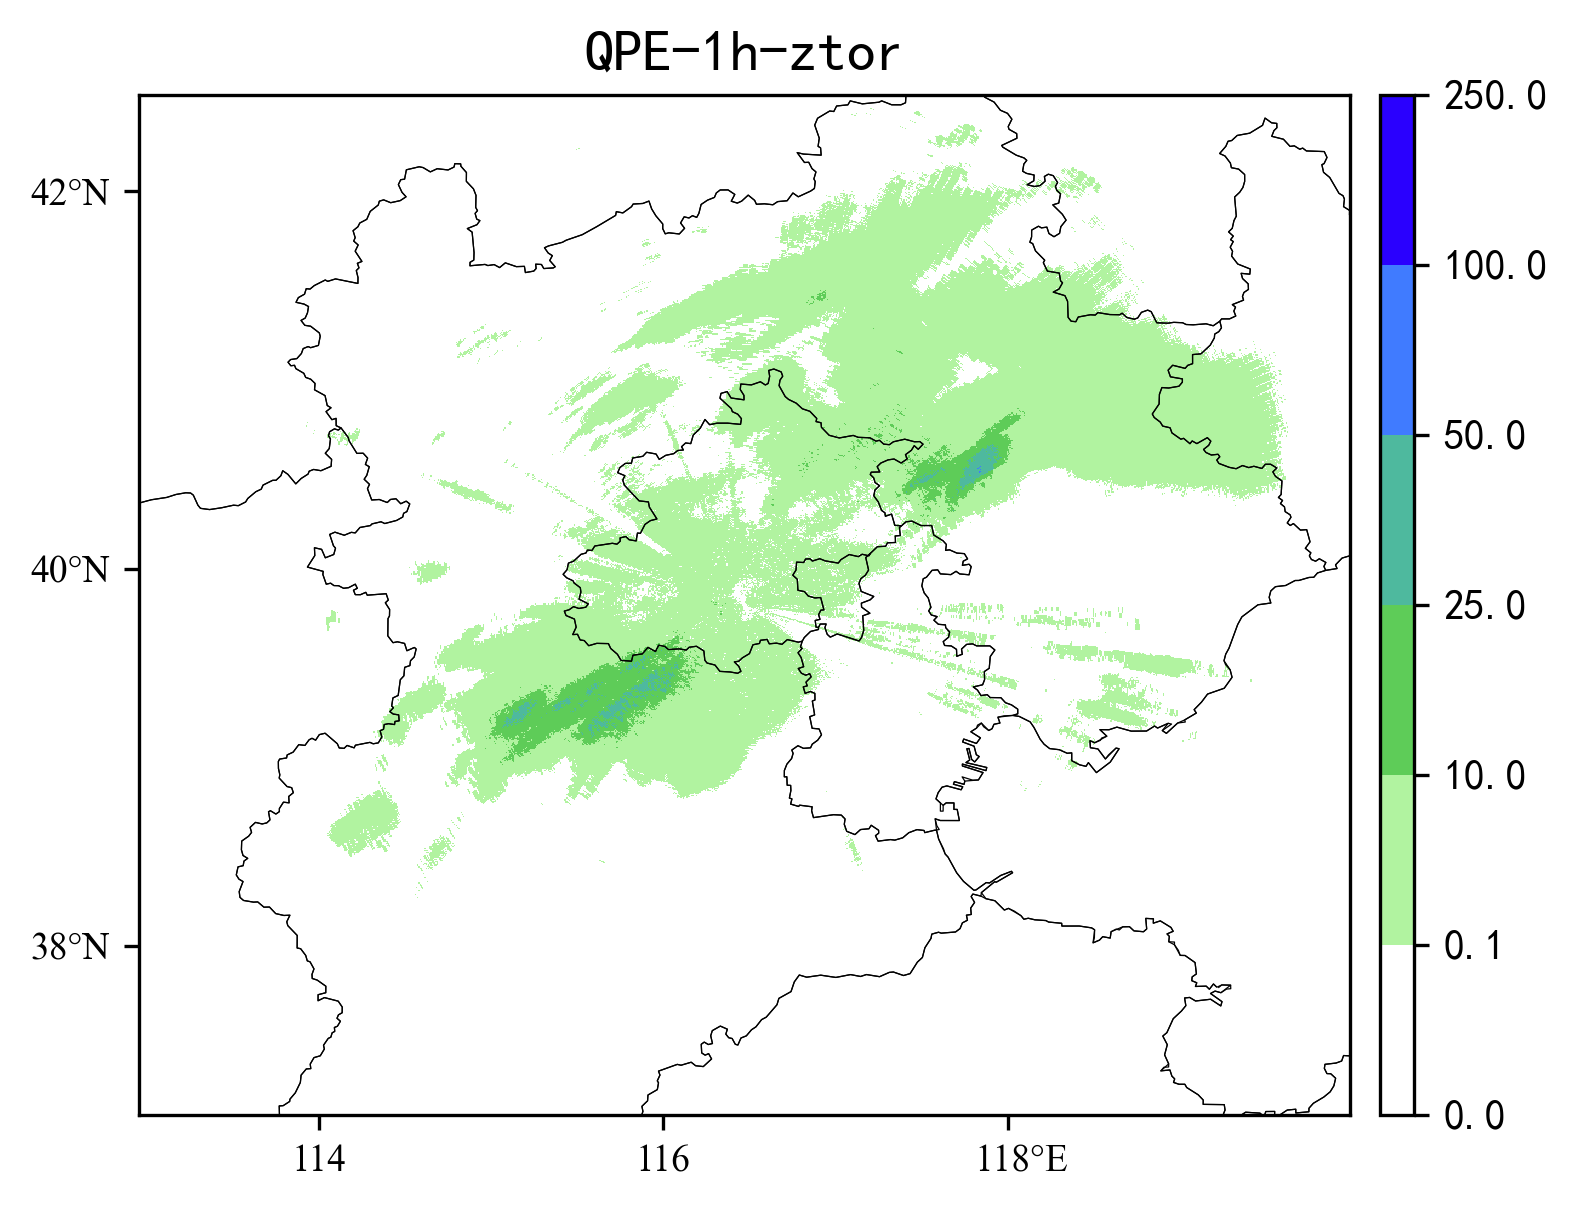

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\ztor_1h.png


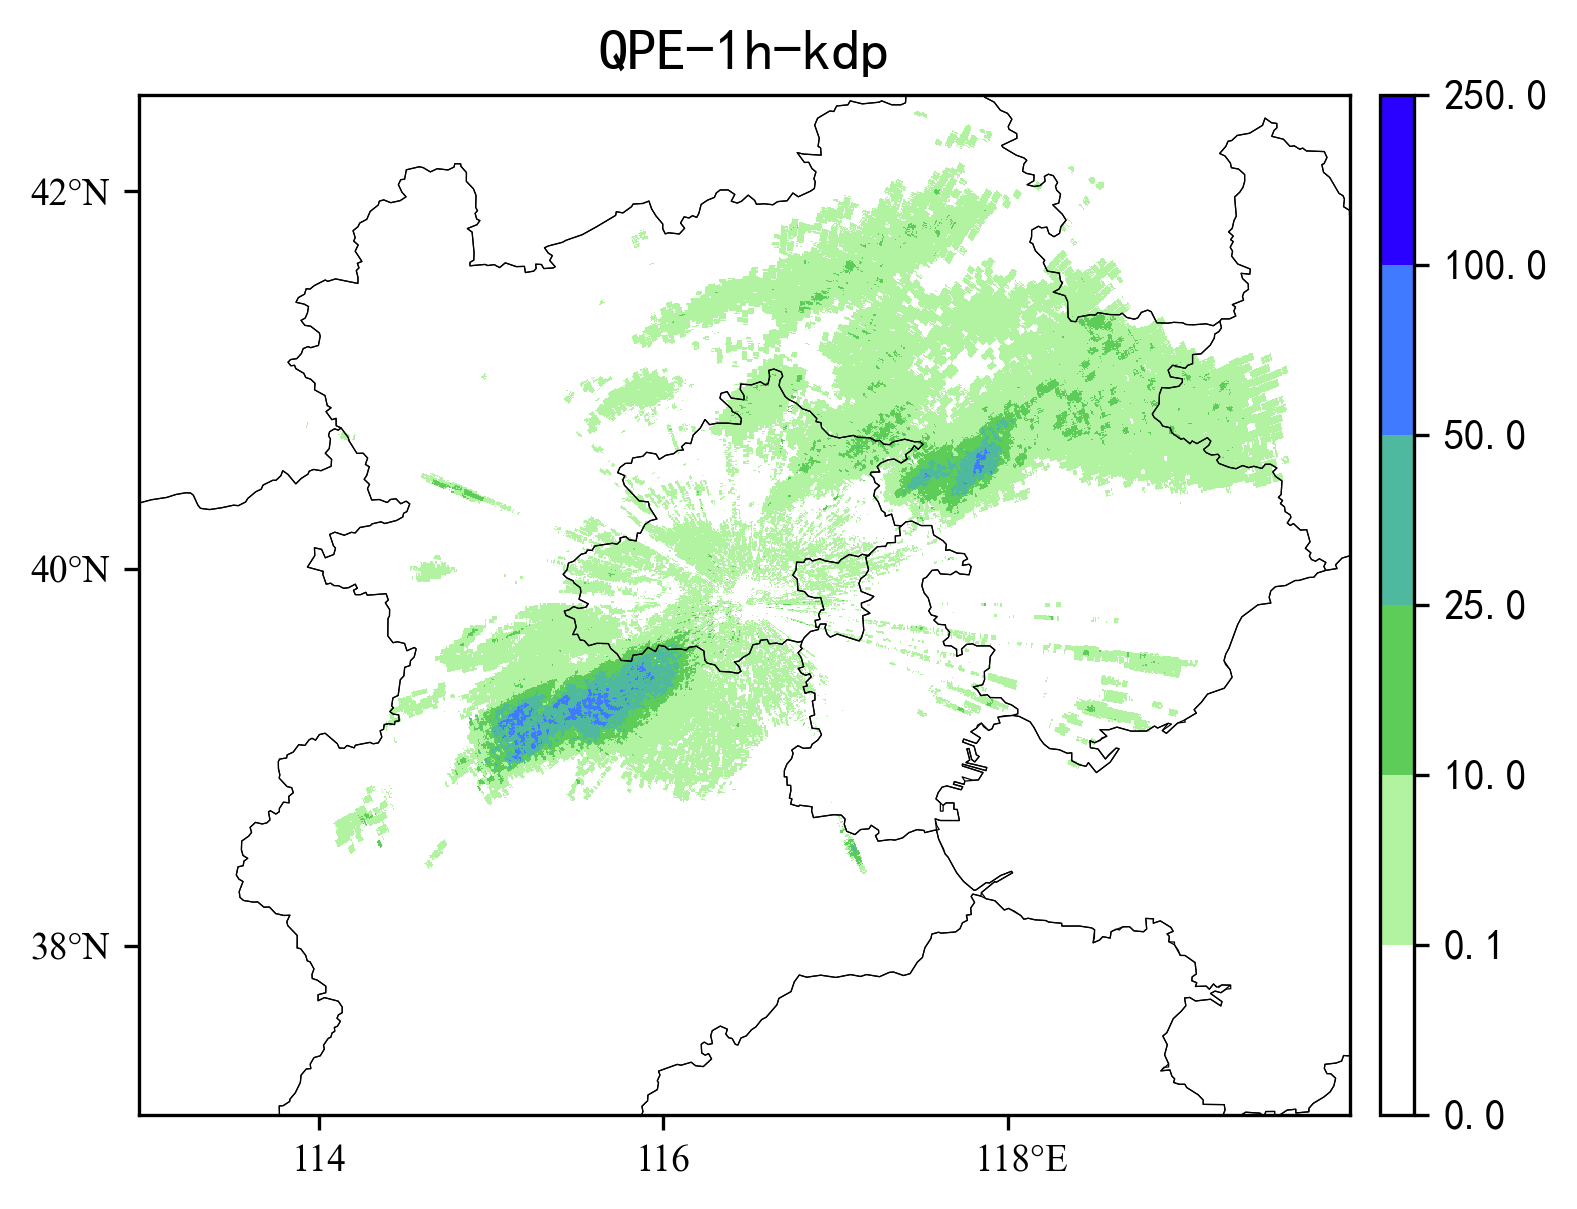

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\kdp_1h.png


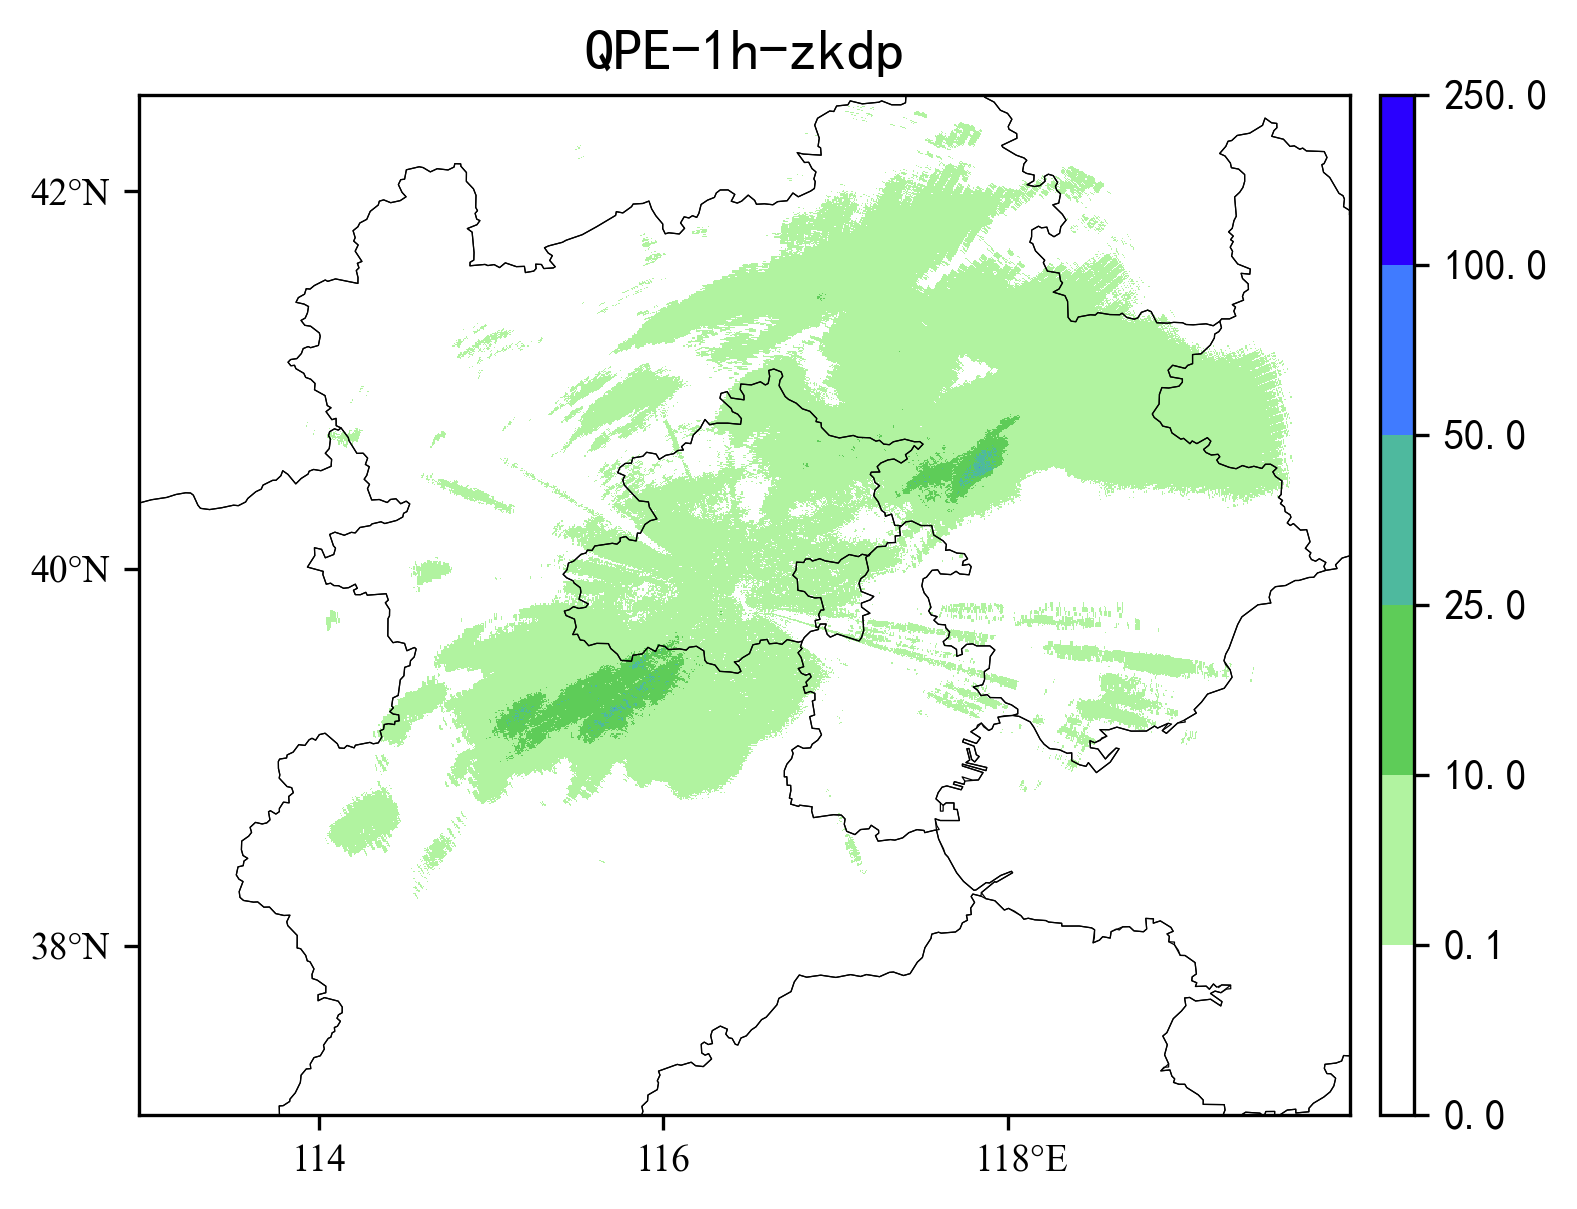

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\zkdp_1h.png


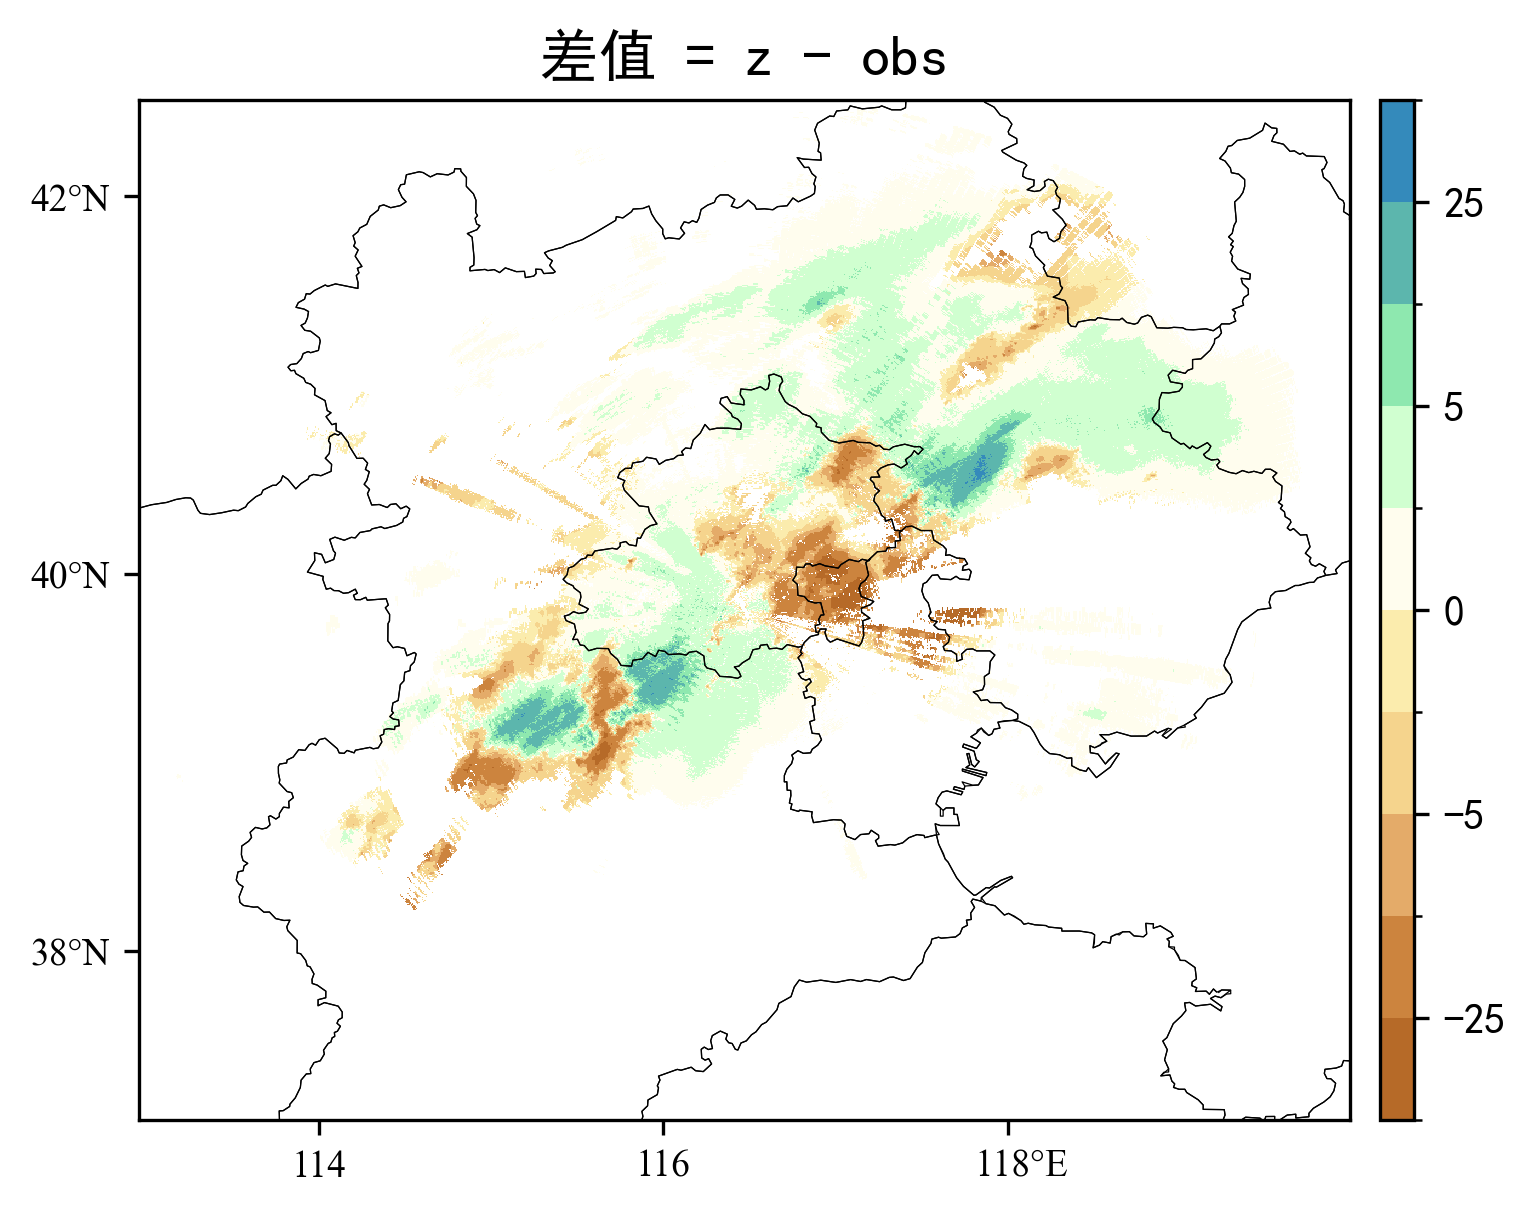

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\diff_z_minus_obs.png


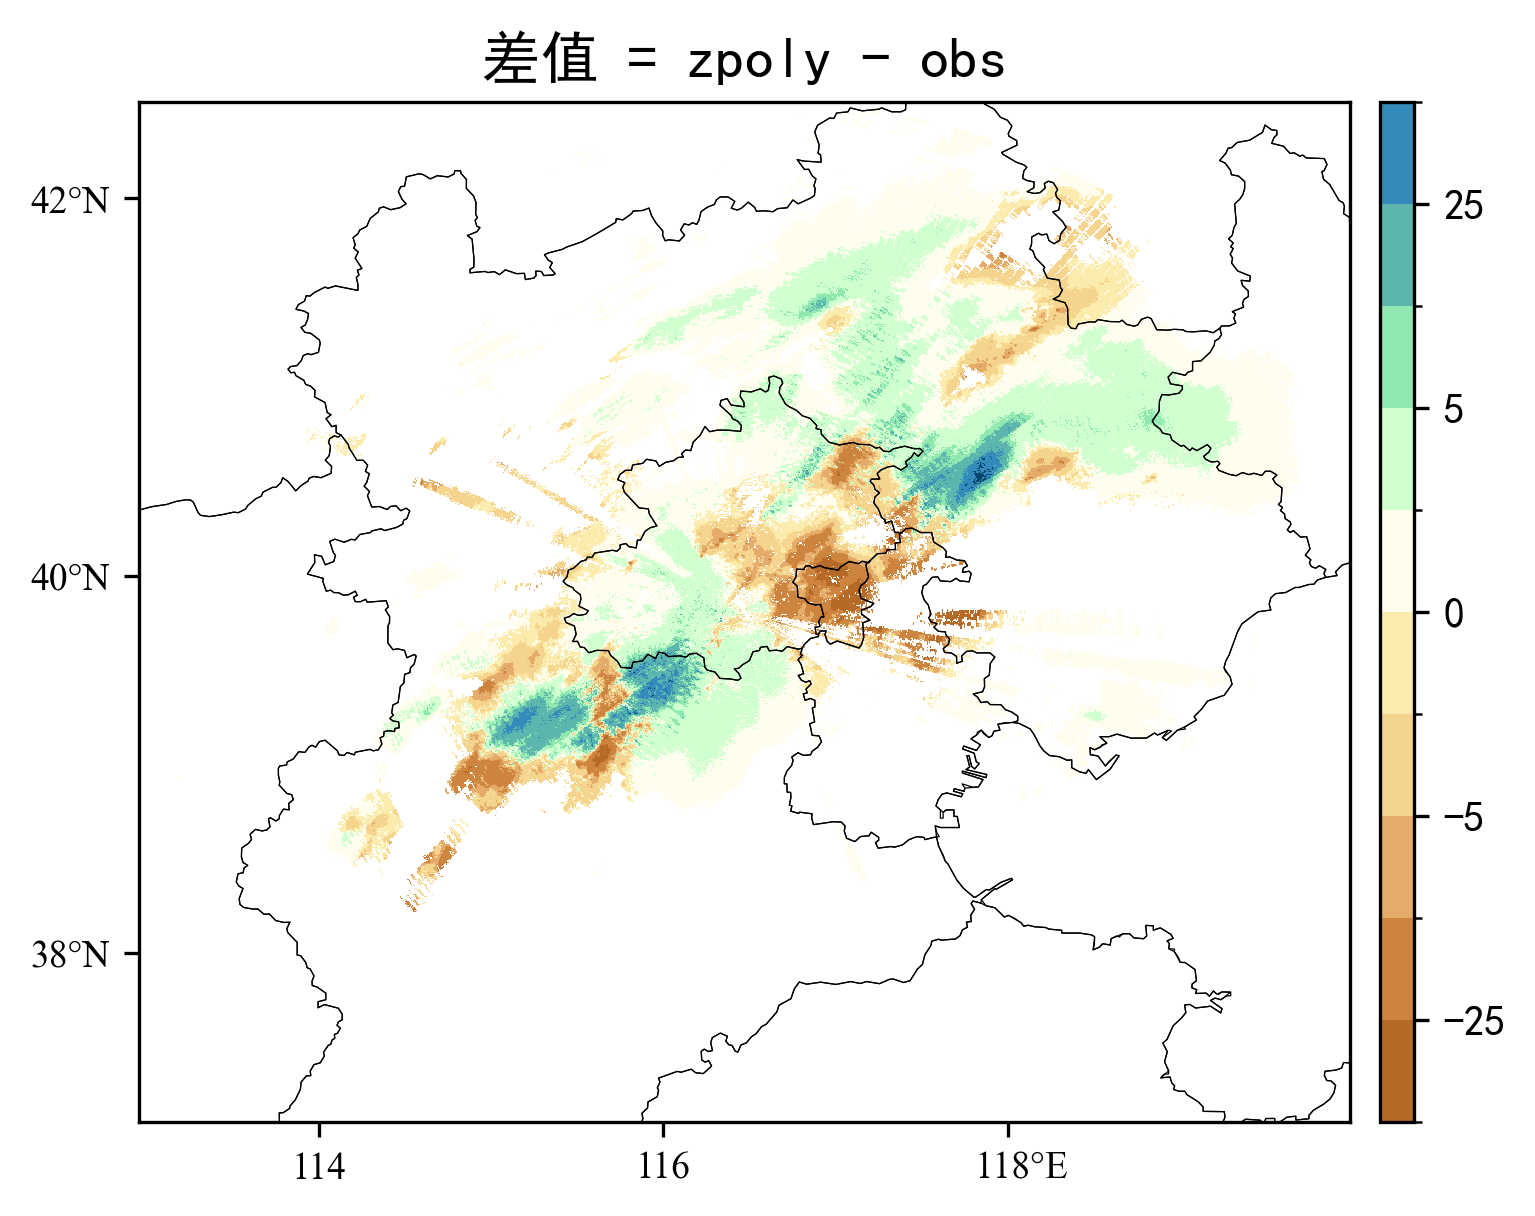

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\diff_zpoly_minus_obs.png


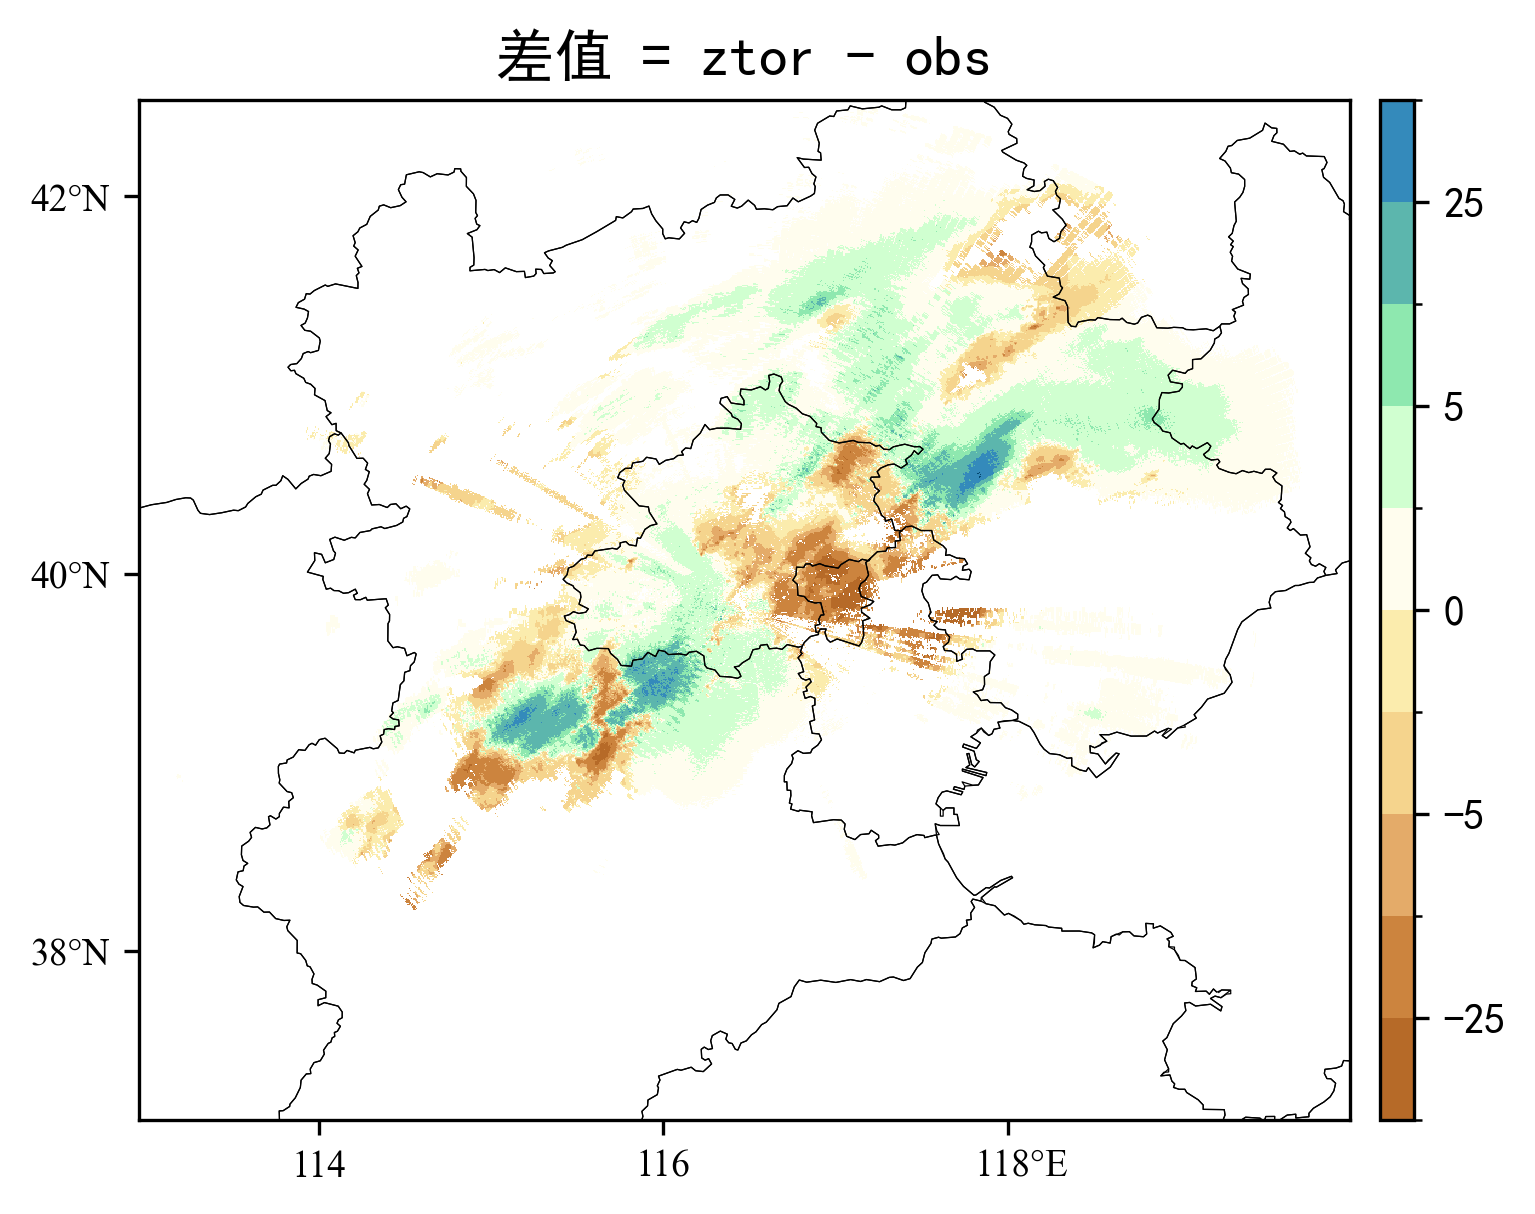

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\diff_ztor_minus_obs.png


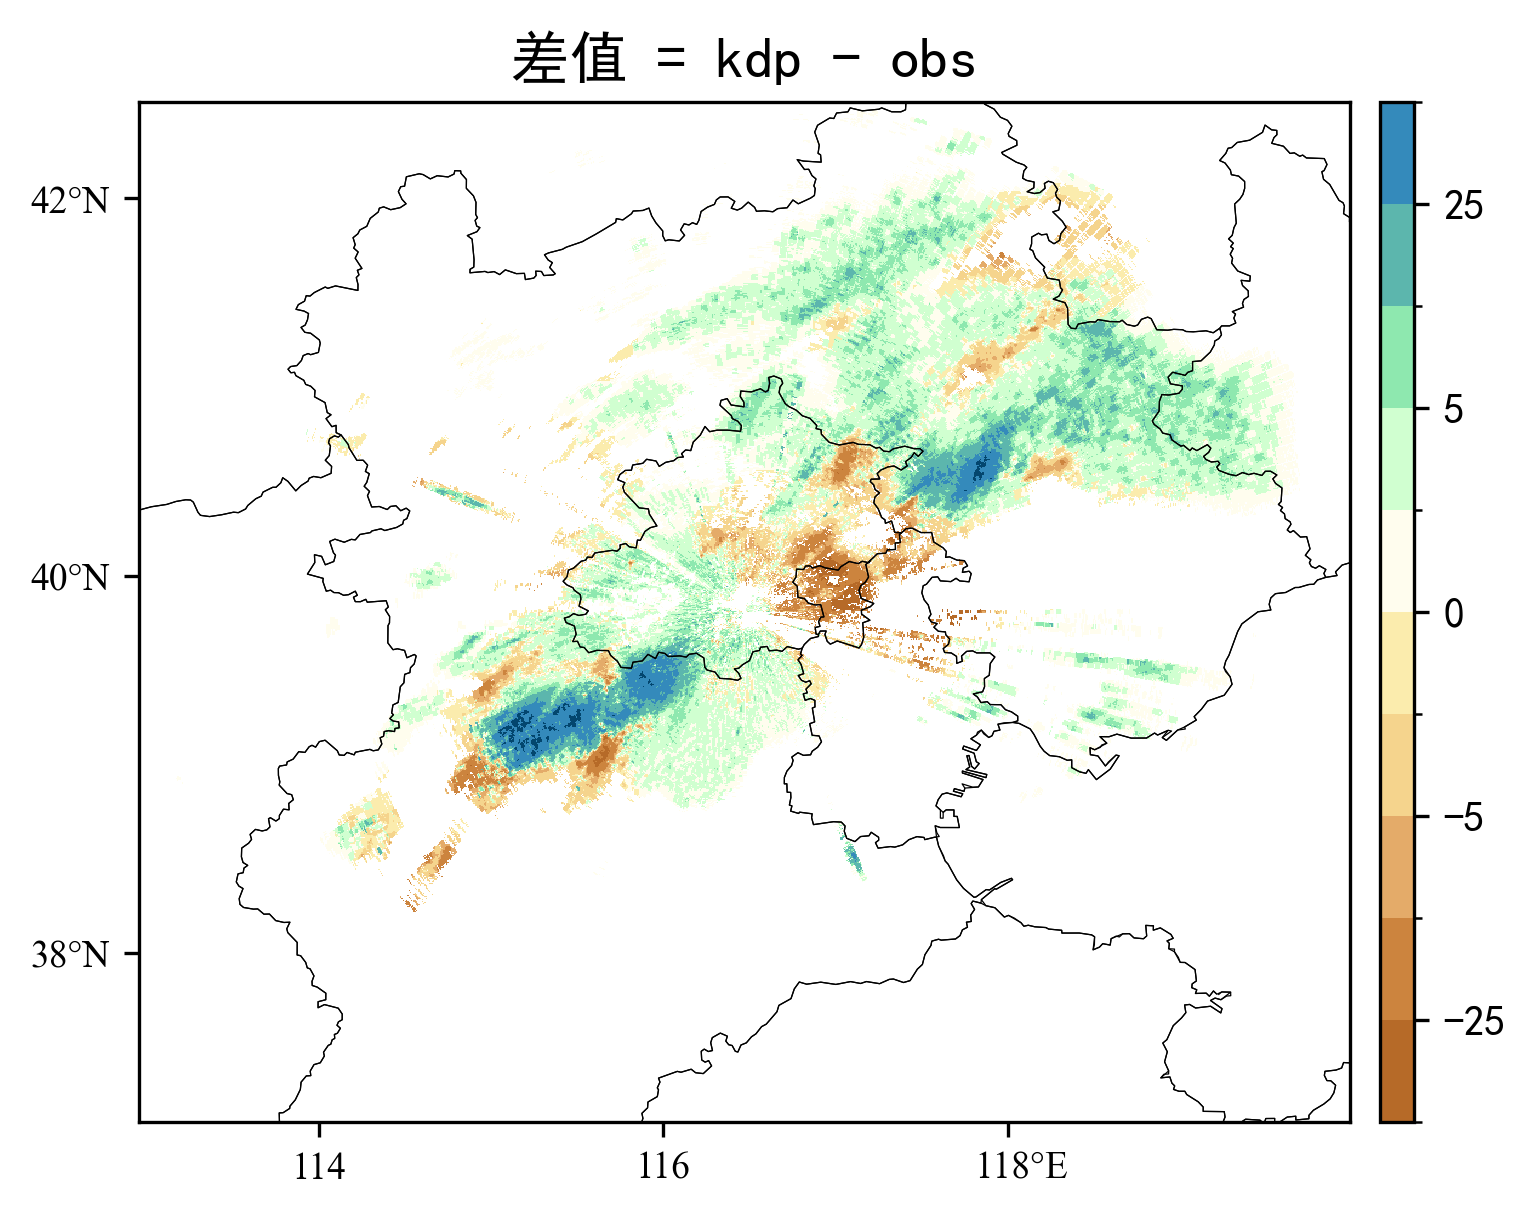

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\diff_kdp_minus_obs.png


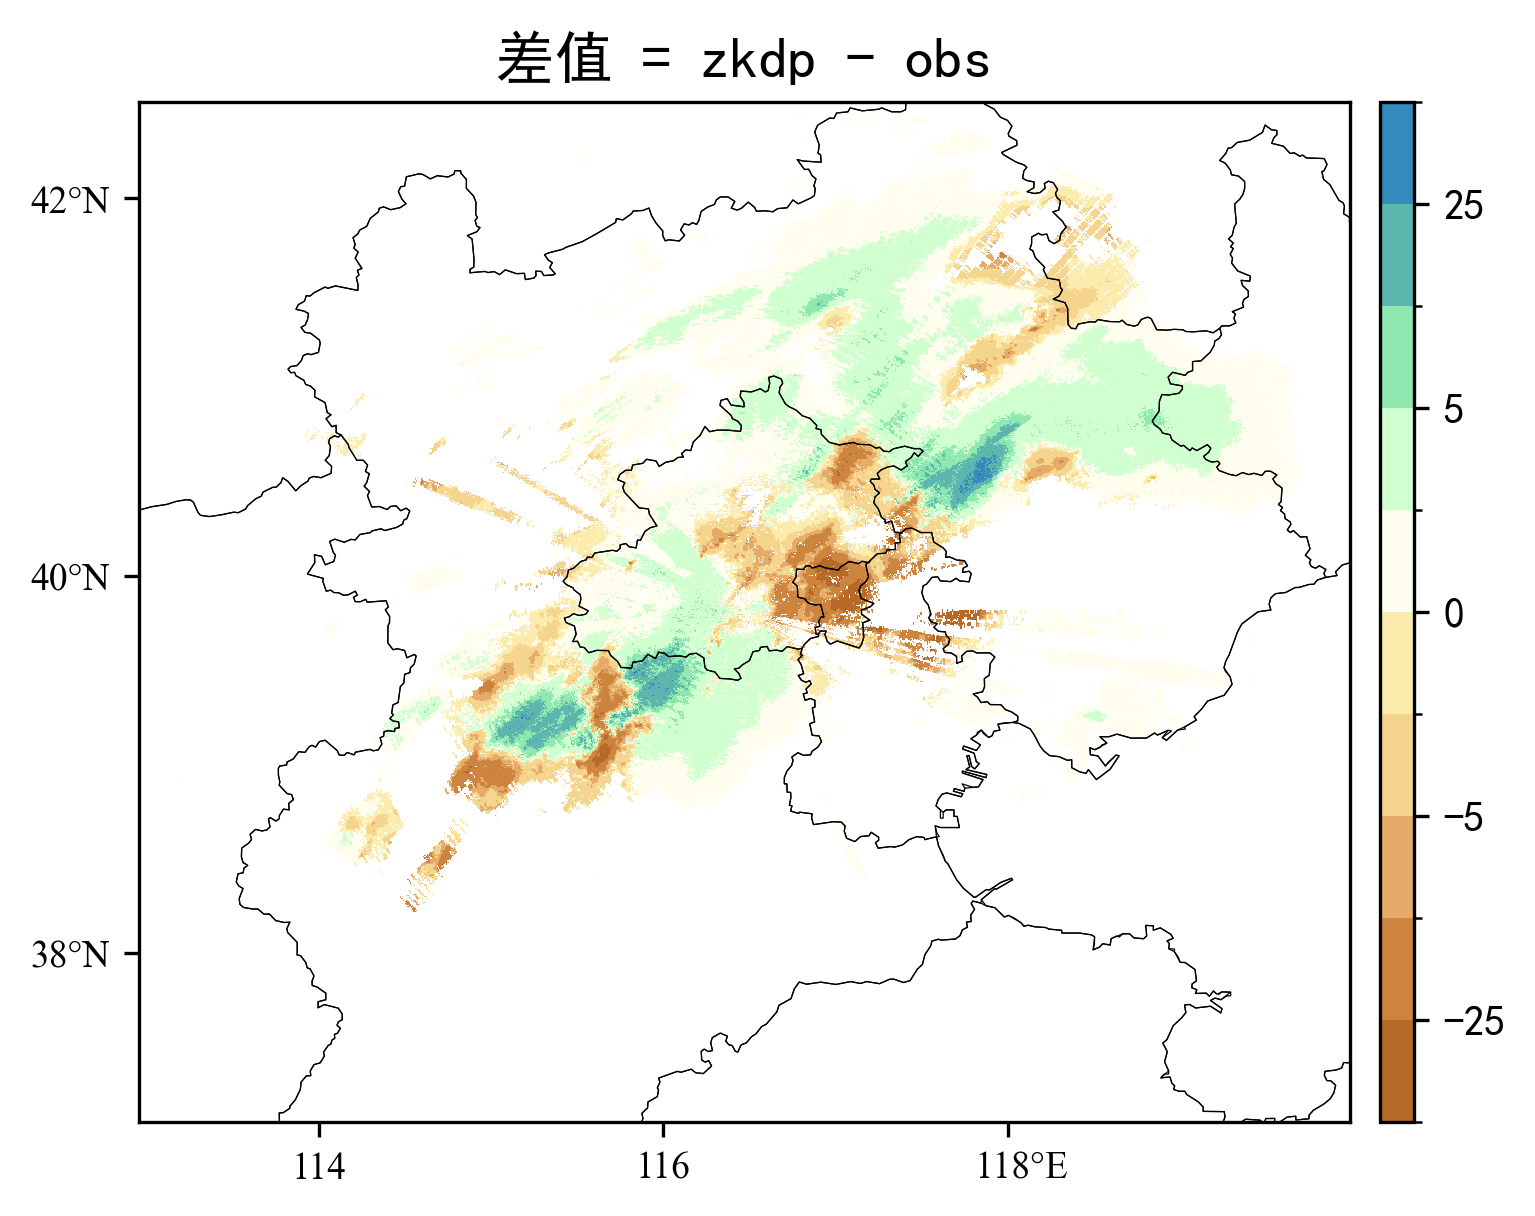

saved D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out\diff_zkdp_minus_obs.png


In [7]:
cmap, _, _, _ = create_qpe_discrete_cmap()
clevs = [0.0, 0.1, 10.0, 25.0, 50.0, 100.0, 250.0]
cmap_err, _ = get_cmap_and_clevs_by_element_name("rain_1h_error")
clevs_err = [-50, -25, -10, -5, -1, 0, 1, 5, 10, 25, 50]

lat = np.asarray(template_da.lat.values)
lon = np.asarray(template_da.lon.values)
box = valid_data_box([obs2d, *hourly.values()], lat, lon)

plot_list = [("obs", obs_on_radar, "实况-1h")] + [
    (name, hourly_da[name], f"QPE-1h-{name}") for name in METHOD_SPECS
]

for key, da, title in plot_list:
    save_path = OUT_DIR / f"{key}_1h.png"
    pcolormesh_2d_grid(
        da.sel(**box),
        save_path=str(save_path),
        title=title,
        cmap=cmap,
        clevs=clevs,
        add_county_line=False,
        add_worldmap=False,
        show=True,
    )
    print("saved", save_path)

# 误差场：方法 − 实况
for name in METHOD_SPECS:
    diff = hourly_da[name].copy(deep=True)
    diff.values = (squeeze2d(hourly_da[name]) - obs2d).reshape(diff.shape)
    diff.name = f"diff_{name}"
    diff.attrs["units"] = "mm"
    save_path = OUT_DIR / f"diff_{name}_minus_obs.png"
    pcolormesh_2d_grid(
        diff.sel(**box),
        save_path=str(save_path),
        title=f"差值 = {name} - obs",
        cmap=cmap_err,
        clevs=clevs_err,
        add_county_line=False,
        add_worldmap=False,
        show=True,
    )
    print("saved", save_path)

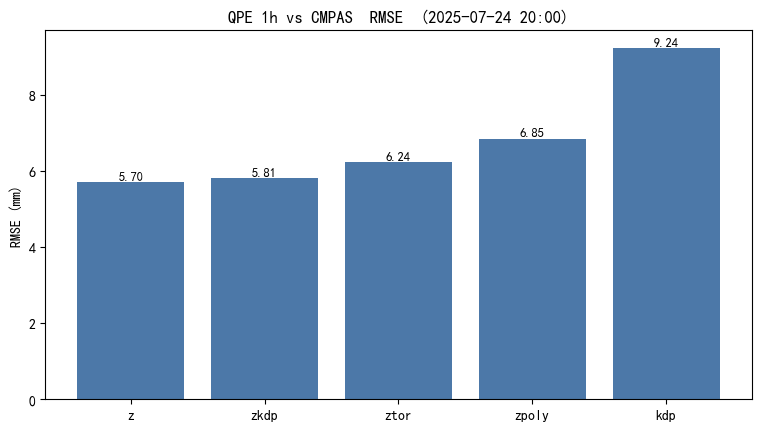

全部输出目录: D:\workspace\test\00temp\radar_qpe_retrieval\nbs\_qpe_hourly_rmse_out


In [8]:
# RMSE 柱状图
fig, ax = plt.subplots(figsize=(7.5, 4.2), constrained_layout=True)
order = stats_df["method"].tolist()
vals = stats_df["rmse"].tolist()
ax.bar(order, vals, color="#4C78A8")
ax.set_ylabel("RMSE (mm)")
ax.set_title(f"QPE 1h vs CMPAS  RMSE  ({hour_end:%Y-%m-%d %H:%M})")
for x, y in zip(order, vals):
    ax.text(x, y, f"{y:.2f}", ha="center", va="bottom", fontsize=9)
fig.savefig(OUT_DIR / "rmse_bar.png", dpi=140)
plt.show()
print("全部输出目录:", OUT_DIR)